# GBP/USD — 7-Day Forecast (Multi-Horizon Price)

Model: Ridge vs Linear Regression

Target: Close.shift(-1) s/d Close.shift(-7)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
PAIR = "GBPUSD=X"
PAIR_NAME = "GBP/USD"
START_DATE = "2005-01-01"
HORIZONS = list(range(1, 8))

OUTPUT_DIR = Path("outputs_revisi")
OUTPUT_DIR.mkdir(exist_ok=True)

In [3]:
raw = yf.download(PAIR, start=START_DATE, progress=False, auto_adjust=False)

raw.columns = ['_'.join(col).strip() for col in raw.columns.values]
raw.columns = [c.replace(f'_{PAIR}', '') for c in raw.columns]

df = raw.reset_index().copy()
if 'Date_' in df.columns:
    df = df.rename(columns={'Date_': 'Date'})

if "Adj Close" in df.columns and "Close" not in df.columns:
    df = df.rename(columns={"Adj Close": "Close"})

needed_cols = ["Date", "Open", "High", "Low", "Close"]
missing = [c for c in needed_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}. Got: {list(df.columns)}")

df = df[needed_cols].dropna().copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print(f"Data: {len(df)} rows")
print(df.tail(3))

Data: 5583 rows
           Date      Open      High       Low     Close
5580 2026-06-23  1.324644  1.325030  1.318635  1.324714
5581 2026-06-24  1.320080  1.320934  1.314302  1.320010
5582 2026-06-25  1.316777  1.318565  1.315911  1.317957


In [4]:
def calculate_rsi(close, period=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(period).mean()
    avg_loss = loss.rolling(period).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi


def add_features(data):
    out = data.copy().sort_values("Date").reset_index(drop=True)

    out["return"] = out["Close"].pct_change()

    out["lag1"] = out["Close"].shift(1)
    out["lag7"] = out["Close"].shift(7)

    out["ma7"] = out["Close"].rolling(7).mean()
    out["ma21"] = out["Close"].rolling(21).mean()

    out["ma7_gap"] = (out["ma7"] - out["Close"]) / out["Close"]
    out["ma21_gap"] = (out["ma21"] - out["Close"]) / out["Close"]

    out["volatility7"] = out["return"].rolling(7).std()

    out["range_pct"] = (out["High"] - out["Low"]) / out["Close"]

    out["rsi14"] = calculate_rsi(out["Close"], 14)

    out["day_of_week"] = out["Date"].dt.dayofweek
    out["dow_sin"] = np.sin(2 * np.pi * out["day_of_week"] / 5)
    out["dow_cos"] = np.cos(2 * np.pi * out["day_of_week"] / 5)

    return out


feature_df = add_features(df)

FEATURES = [
    "Open", "High", "Low", "Close",
    "return", "lag1", "lag7",
    "ma7", "ma21",
    "ma7_gap", "ma21_gap",
    "volatility7", "range_pct",
    "rsi14",
    "dow_sin", "dow_cos"
]

print(f"Features: {len(FEATURES)}")
feature_df[["Date", "Close", "return", "ma7", "ma21", "rsi14"]].tail()

Features: 16


,Date,Close,return,ma7,ma21,rsi14
5578,2026-06-19,1.320202,-0.007459,1.336732,1.340758,26.916765
5579,2026-06-22,1.320795,0.000449,1.334531,1.339688,26.570811
5580,2026-06-23,1.324714,0.002967,1.332150,1.338572,31.875721
5581,2026-06-24,1.320010,-0.003551,1.328584,1.337161,30.800698
5582,2026-06-25,1.317957,-0.001555,1.325206,1.335848,29.774276


In [5]:
for h in HORIZONS:
    feature_df[f"target_price_{h}d"] = feature_df["Close"].shift(-h)
    feature_df[f"target_date_{h}d"] = feature_df["Date"].shift(-h)

TARGET_COLS = [f"target_price_{h}d" for h in HORIZONS]

model_df = feature_df.dropna(subset=FEATURES + TARGET_COLS).copy()

X = model_df[FEATURES]
y = model_df[TARGET_COLS]

print(f"Train data: {len(model_df)} rows")
print(f"X shape: {X.shape}, y shape: {y.shape}")
model_df[["Date", "Close"] + TARGET_COLS].tail()

Train data: 5556 rows
X shape: (5556, 16), y shape: (5556, 7)


,Date,Close,target_price_1d,target_price_2d,target_price_3d,target_price_4d,target_price_5d,target_price_6d,target_price_7d
5571,2026-06-10,1.337220,1.336202,1.341382,1.344972,1.341599,1.342642,1.330123,1.320202
5572,2026-06-11,1.336202,1.341382,1.344972,1.341599,1.342642,1.330123,1.320202,1.320795
5573,2026-06-12,1.341382,1.344972,1.341599,1.342642,1.330123,1.320202,1.320795,1.324714
5574,2026-06-15,1.344972,1.341599,1.342642,1.330123,1.320202,1.320795,1.324714,1.320010
5575,2026-06-16,1.341599,1.342642,1.330123,1.320202,1.320795,1.324714,1.320010,1.317957


In [6]:
split_idx = int(len(model_df) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]
test_meta = model_df.iloc[split_idx:].copy()

print(f"Train: {model_df.iloc[0]['Date'].date()} s/d {model_df.iloc[split_idx-1]['Date'].date()} ({len(X_train)} rows)")
print(f"Test:  {model_df.iloc[split_idx]['Date'].date()} s/d {model_df.iloc[-1]['Date'].date()} ({len(X_test)} rows)")

Train: 2005-01-31 s/d 2022-03-04 (4444 rows)
Test:  2022-03-07 s/d 2026-06-16 (1112 rows)


In [7]:
ridge_default = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridge_grid = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

linear = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

param_grid = {
    "ridge__alpha": np.logspace(-3, 3, 13),
    "ridge__fit_intercept": [True, False]
}

tscv = TimeSeriesSplit(n_splits=5)

grid = GridSearchCV(
    estimator=ridge_grid,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

print("Training models...")
ridge_default.fit(X_train, y_train)
grid.fit(X_train, y_train)
linear.fit(X_train, y_train)

ridge_best = grid.best_estimator_
print(f"Ridge best params: {grid.best_params_}")
print(f"Best CV MAE: {-grid.best_score_:.6f}")

Training models...
Ridge best params: {'ridge__alpha': np.float64(0.31622776601683794), 'ridge__fit_intercept': True}
Best CV MAE: 0.012922


In [8]:
def evaluate_predictions(name, y_true_price, y_pred_price, current_close, horizons):
    rows = []
    for idx, h in enumerate(horizons):
        actual = y_true_price[:, idx]
        pred = y_pred_price[:, idx]

        mae = mean_absolute_error(actual, pred)
        rmse = np.sqrt(mean_squared_error(actual, pred))
        r2 = r2_score(actual, pred)

        mae_pips = mae * 10000

        future_ret = (actual - current_close) / current_close
        pred_ret = (pred - current_close) / current_close
        direction_acc = np.mean(np.sign(future_ret) == np.sign(pred_ret))

        within_5pip = np.abs(pred - actual) <= 0.0005
        hit_rate = np.mean(within_5pip)

        rows.append({
            "model": name,
            "horizon": h,
            "MAE_pips": round(mae_pips, 2),
            "R2": round(r2, 4),
            "direction_accuracy": round(direction_acc, 4),
            "hit_rate_5pip": round(hit_rate, 4)
        })
    return pd.DataFrame(rows)


current_close_test = test_meta["Close"].to_numpy()

pred_default = ridge_default.predict(X_test)
pred_best = ridge_best.predict(X_test)
pred_linear = linear.predict(X_test)
y_true = y_test.to_numpy()

eval_default = evaluate_predictions("Ridge (alpha=1)", y_true, pred_default, current_close_test, HORIZONS)
eval_best = evaluate_predictions("Ridge (grid search)", y_true, pred_best, current_close_test, HORIZONS)
eval_linear = evaluate_predictions("Linear Regression", y_true, pred_linear, current_close_test, HORIZONS)

eval_df = pd.concat([eval_default, eval_best, eval_linear], ignore_index=True)
eval_df

,model,horizon,MAE_pips,R2,direction_accuracy,hit_rate_5pip
0,Ridge (alpha=1),1,40.90,0.9905,0.7329,0.0926
1,Ridge (alpha=1),2,66.21,0.9758,0.6214,0.0459
2,Ridge (alpha=1),3,82.93,0.9623,0.5728,0.0468
3,Ridge (alpha=1),4,97.56,0.9485,0.5432,0.0360
4,Ridge (alpha=1),5,109.35,0.9361,0.5234,0.0297
5,Ridge (alpha=1),6,120.29,0.9235,0.5243,0.0315
6,Ridge (alpha=1),7,129.35,0.9127,0.5225,0.0297
7,Ridge (grid search),1,39.03,0.9912,0.7572,0.1097
8,Ridge (grid search),2,64.95,0.9766,0.6385,0.0468
9,Ridge (grid search),3,82.09,0.9630,0.5827,0.0432


In [9]:
summary = (
    eval_df
    .groupby("model")[["MAE_pips", "R2", "direction_accuracy", "hit_rate_5pip"]]
    .mean()
    .sort_values("MAE_pips")
)
print("=== Average Across All Horizons ===")
summary

=== Average Across All Horizons ===


,MAE_pips,R2,direction_accuracy,hit_rate_5pip
model,,,,
Linear Regression,91.641429,0.950300,0.600214,0.045629
Ridge (grid search),91.650000,0.950500,0.593786,0.046400
Ridge (alpha=1),92.370000,0.949914,0.577214,0.044600


In [10]:
best_model_name = summary.index[0]
best_model = {
    "Ridge (alpha=1)": ridge_default,
    "Ridge (grid search)": ridge_best,
    "Linear Regression": linear
}[best_model_name]
print(f"Best model: {best_model_name}")

Best model: Linear Regression


## Predicted vs Actual (Horizon 7)

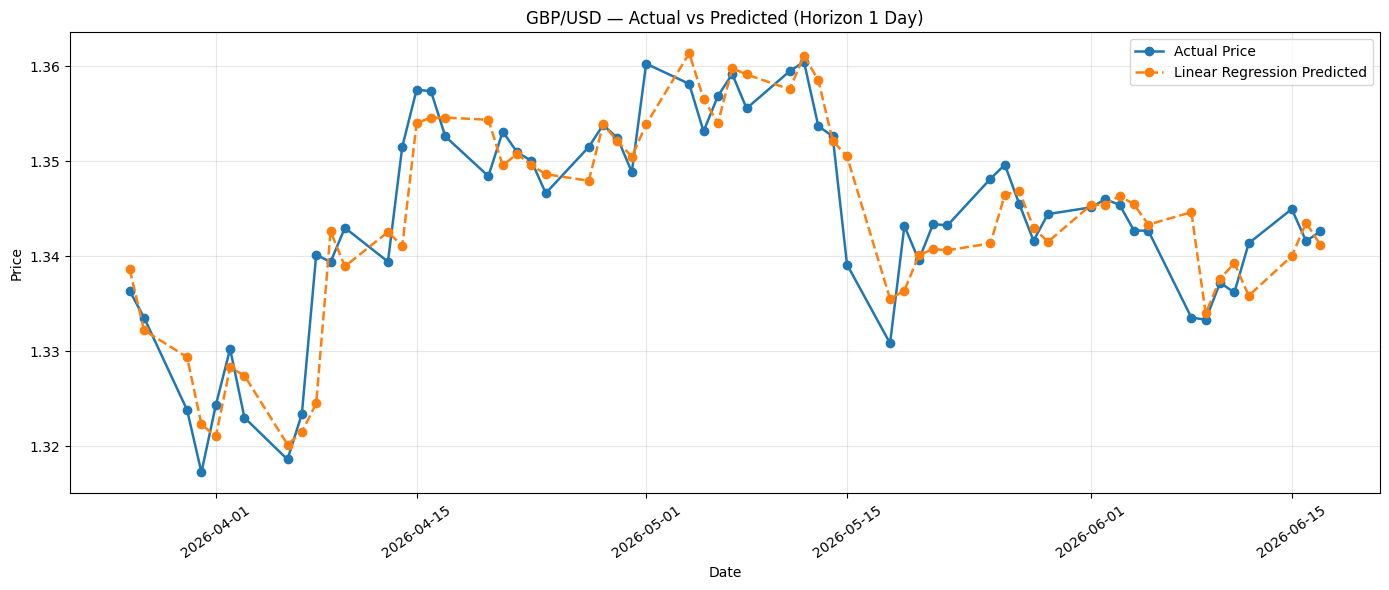

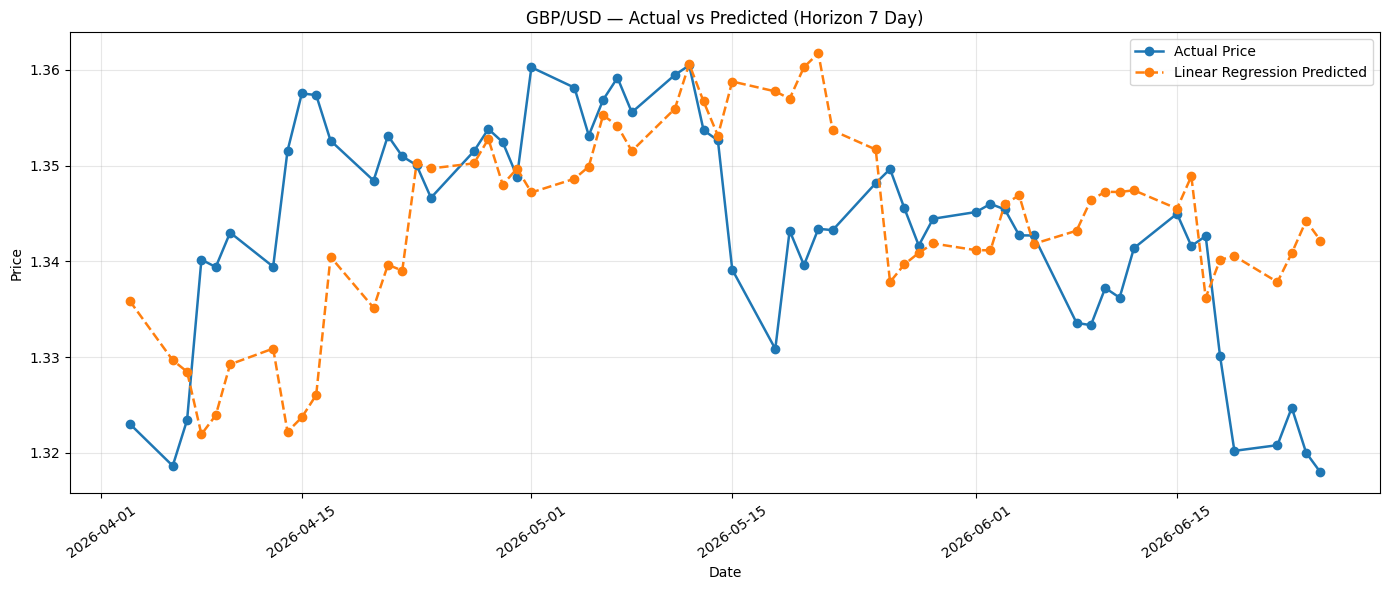

In [11]:
def plot_actual_vs_predicted(horizon=7, last_n=60):
    h_idx = HORIZONS.index(horizon)
    
    actual_h = y_test.to_numpy()[:, h_idx]
    pred_h = best_model.predict(X_test)[:, h_idx]

    plot_dates = pd.to_datetime(test_meta[f"target_date_{horizon}d"])

    plot_df = pd.DataFrame({
        "Date": plot_dates,
        "Actual": actual_h,
        "Predicted": pred_h
    }).dropna().tail(last_n)

    plt.figure(figsize=(14, 6))
    plt.plot(plot_df["Date"], plot_df["Actual"], marker="o", linewidth=1.8, label="Actual Price")
    plt.plot(plot_df["Date"], plot_df["Predicted"], marker="o", linestyle="--", linewidth=1.8, label=f"{best_model_name} Predicted")
    plt.title(f"{PAIR_NAME} — Actual vs Predicted (Horizon {horizon} Day)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

# Plot horizon 1 dan 7
plot_actual_vs_predicted(horizon=1, last_n=60)
plot_actual_vs_predicted(horizon=7, last_n=60)

In [12]:
final_model = clone(best_model)
final_model.fit(X, y)

model_bundle = {
    "model": final_model,
    "features": FEATURES,
    "horizons": HORIZONS,
    "target_type": "multi_horizon_price",
    "pair": PAIR,
    "pair_name": PAIR_NAME,
    "best_params": getattr(grid, 'best_params_', {}),
    "model_name": best_model_name
}

model_path = OUTPUT_DIR / "ridge_gbpusd_multihorizon.pkl"
features_path = OUTPUT_DIR / "features_gbpusd.json"

joblib.dump(model_bundle, model_path)
with open(features_path, "w") as f:
    json.dump(FEATURES, f)

print(f"Model saved: {model_path}")
print(f"Features saved: {features_path}")

Model saved: outputs_revisi\ridge_gbpusd_multihorizon.pkl
Features saved: outputs_revisi\features_gbpusd.json


In [13]:
latest_row = feature_df.dropna(subset=FEATURES).iloc[-1:].copy()
latest_X = latest_row[FEATURES]

latest_date = pd.to_datetime(latest_row["Date"].iloc[0])
latest_close = float(latest_row["Close"].iloc[0])

forecast_prices = final_model.predict(latest_X)[0]

future_dates = pd.bdate_range(latest_date + pd.offsets.BDay(1), periods=len(HORIZONS))

forecast_df = pd.DataFrame({
    "horizon": HORIZONS,
    "date": future_dates,
    "forecast_price": forecast_prices
})
forecast_df["last_close"] = latest_close
forecast_df["last_date"] = latest_date.strftime("%Y-%m-%d")
forecast_df["change_from_close"] = ((forecast_df["forecast_price"] / latest_close) - 1) * 100

forecast_df

,horizon,date,forecast_price,last_close,last_date,change_from_close
0,1,2026-06-26,1.316197,1.317957,2026-06-25,-0.133517
1,2,2026-06-29,1.315958,1.317957,2026-06-25,-0.151665
2,3,2026-06-30,1.315995,1.317957,2026-06-25,-0.148864
3,4,2026-07-01,1.316454,1.317957,2026-06-25,-0.114024
4,5,2026-07-02,1.317037,1.317957,2026-06-25,-0.069788
5,6,2026-07-03,1.317200,1.317957,2026-06-25,-0.057463
6,7,2026-07-06,1.316628,1.317957,2026-06-25,-0.100868


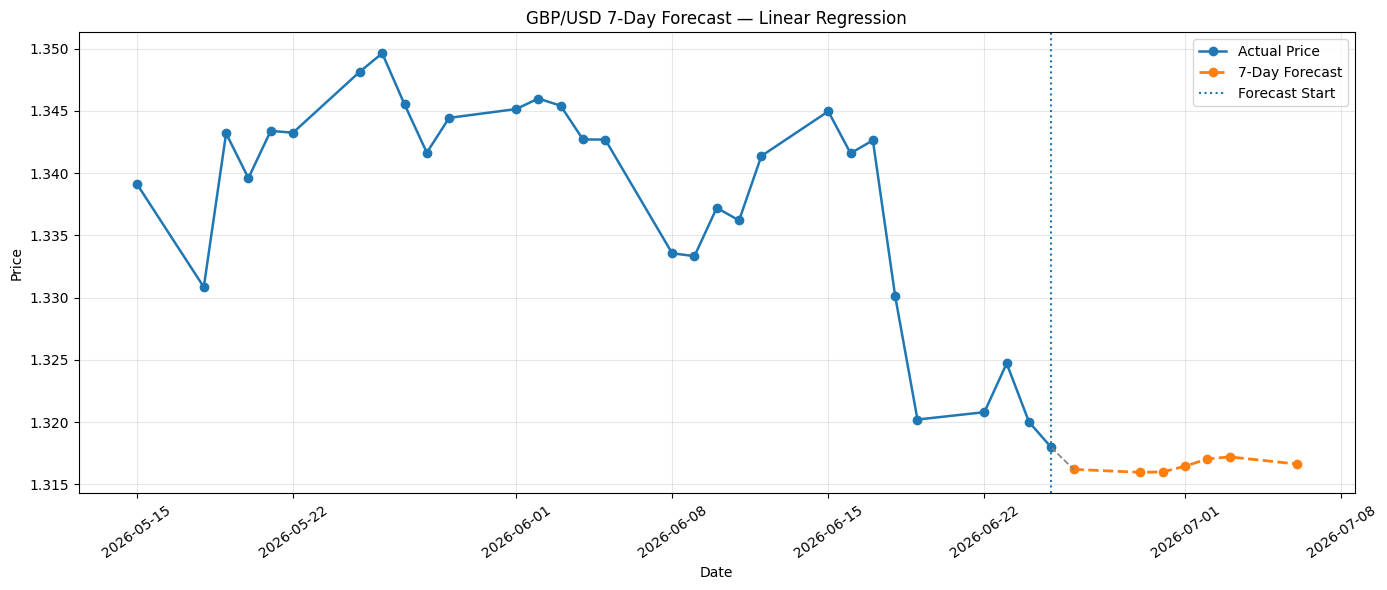

Last close: 1.31796
Forecast day 7: 1.31663
Expected change: -0.1009%


In [14]:
history_plot = feature_df.dropna(subset=["Close"]).tail(30)[["Date", "Close"]].copy()

plt.figure(figsize=(14, 6))
plt.plot(history_plot["Date"], history_plot["Close"], marker="o", linewidth=1.8, label="Actual Price")
plt.plot(forecast_df["date"], forecast_df["forecast_price"], marker="o", linestyle="--", linewidth=2.0, label="7-Day Forecast")

plt.plot(
    [history_plot["Date"].iloc[-1], forecast_df["date"].iloc[0]],
    [history_plot["Close"].iloc[-1], forecast_df["forecast_price"].iloc[0]],
    linestyle="--", linewidth=1.2, color="gray"
)

plt.axvline(history_plot["Date"].iloc[-1], linestyle=":", linewidth=1.5, label="Forecast Start")
plt.title(f"{PAIR_NAME} 7-Day Forecast — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print(f"Last close: {latest_close:.5f}")
print(f"Forecast day 7: {forecast_df['forecast_price'].iloc[-1]:.5f}")
print(f"Expected change: {forecast_df['change_from_close'].iloc[-1]:+.4f}%")

In [15]:
eval_df.to_csv(OUTPUT_DIR / "metrics_gbpusd.csv", index=False)
print(f"\nAll files saved to: {OUTPUT_DIR}/")


All files saved to: outputs_revisi/
